# ML Assignment 2 - Spam E-mail Classification

**Student:** Bhavani S
**BITS ID:** 2026AJ05027

End-to-end workflow: load the UCI **Spambase** corpus, explore it, train five
classifiers (each as a scaling pipeline), evaluate with six metrics, and export the
fitted pipelines + a hold-out CSV for the Streamlit deployment.

Spambase is a **binary** problem: flag an e-mail as spam (1) or legitimate / ham (0)
from 57 word-frequency, character-frequency and capital-run statistics.

## 1. Libraries

In [1]:
import pathlib, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn import metrics

SEED = 7
pd.set_option("display.max_columns", 60)

## 2. Load the corpus

In [2]:
root = pathlib.Path.cwd()
root = root.parent if root.name == "notebooks" else root
df = pd.read_csv(root / "_spam" / "spambase_full.csv")
print("messages:", df.shape[0], "| features:", df.shape[1]-1)
df.head()

messages: 4601 | features: 57


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,is_spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## 3. Exploration

In [3]:
print("Label balance (0 = ham, 1 = spam):")
print(df["is_spam"].value_counts())
print("\nSpam rate: {:.1%}".format(df["is_spam"].mean()))
print("Missing cells:", int(df.isnull().sum().sum()))

Label balance (0 = ham, 1 = spam):
is_spam
0    2788
1    1813
Name: count, dtype: int64

Spam rate: 39.4%
Missing cells: 0


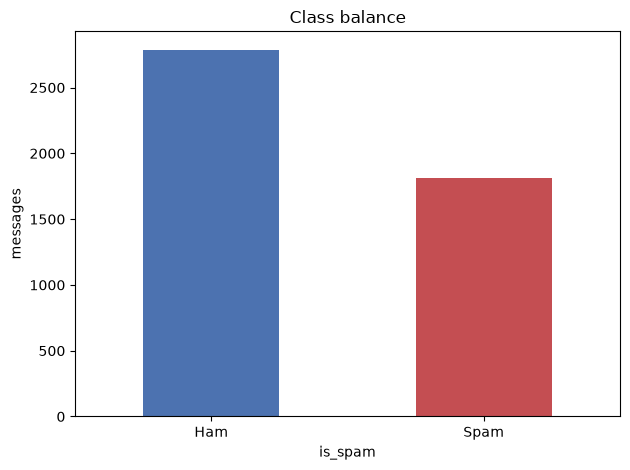

In [4]:
# Class balance bar
counts = df["is_spam"].map({0: "Ham", 1: "Spam"}).value_counts()
counts.plot.bar(color=["#4c72b0", "#c44e52"])
plt.title("Class balance"); plt.ylabel("messages"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

In [5]:
# Which features separate spam from ham most strongly?
means = df.groupby("is_spam").mean().T
means.columns = ["ham_mean", "spam_mean"]
means["gap"] = (means["spam_mean"] - means["ham_mean"]).abs()
top = means.sort_values("gap", ascending=False).head(12)
print("Top 12 most discriminative features (|spam mean - ham mean|):")
top[["ham_mean", "spam_mean"]]

Top 12 most discriminative features (|spam mean - ham mean|):


,ham_mean,spam_mean
capital_run_length_total,161.470947,470.619415
capital_run_length_longest,18.214491,104.393271
capital_run_length_average,2.377301,9.519165
word_freq_george,1.265265,0.001550
word_freq_you,1.270341,2.264539
word_freq_your,0.438702,1.380370
word_freq_hp,0.895473,0.017479
word_freq_free,0.073587,0.518362
word_freq_hpl,0.431994,0.009173
char_freq_!,0.109984,0.513713


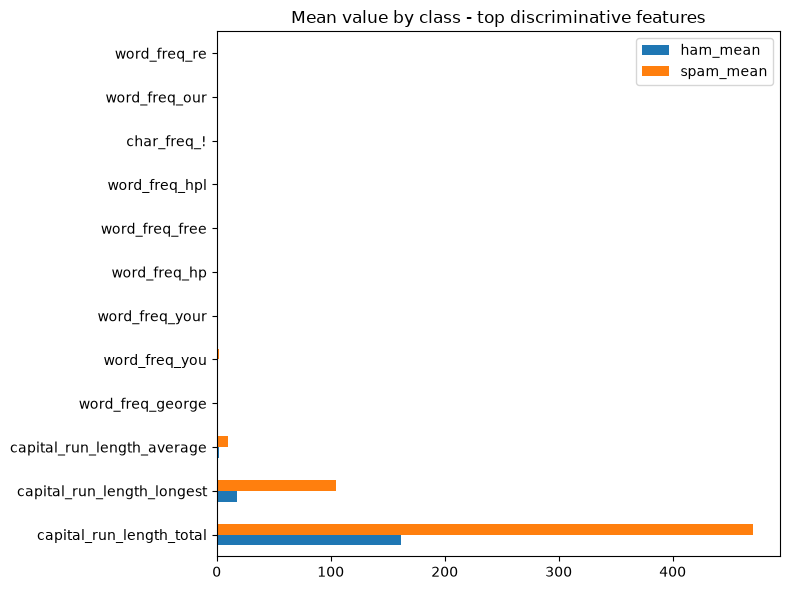

In [6]:
top[["ham_mean", "spam_mean"]].plot.barh(figsize=(8,6))
plt.title("Mean value by class - top discriminative features")
plt.tight_layout(); plt.show()

## 4. Train / hold-out split

A stratified 75/25 split preserves the ham:spam ratio. Every model is a
`Pipeline(StandardScaler -> estimator)` so scaling is learned on the training fold
only and travels with the saved model.

In [7]:
LABEL = "is_spam"
feat_cols = [c for c in df.columns if c != LABEL]
X, y = df[feat_cols], df[LABEL].astype(int)

X_fit, X_hold, y_fit, y_hold = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
print("fit:", X_fit.shape, "| hold-out:", X_hold.shape)

fit: (3450, 57) | hold-out: (1151, 57)


## 5. The five classifiers (as pipelines)

In [8]:
def make(est): return Pipeline([("scaler", StandardScaler()), ("clf", est)])

zoo = {
    "Logistic Regression": make(LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)),
    "Decision Tree": make(DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=SEED)),
    "K-Nearest Neighbors": make(KNeighborsClassifier(n_neighbors=11, weights="distance")),
    "Naive Bayes": make(GaussianNB()),
    "Support Vector Machine": make(SVC(C=2.0, kernel="rbf", probability=True, random_state=SEED)),
}
list(zoo)

['Logistic Regression',
 'Decision Tree',
 'K-Nearest Neighbors',
 'Naive Bayes',
 'Support Vector Machine']

## 6. Fit, evaluate (6 metrics) and save each pipeline

In [9]:
def six_metrics(pipe, Xt, yt):
    pred = pipe.predict(Xt)
    try:
        auc = metrics.roc_auc_score(yt, pipe.predict_proba(Xt)[:,1])
    except Exception:
        auc = np.nan
    return {
        "Accuracy": metrics.accuracy_score(yt, pred),
        "AUC": auc,
        "Precision": metrics.precision_score(yt, pred, zero_division=0),
        "Recall": metrics.recall_score(yt, pred, zero_division=0),
        "F1": metrics.f1_score(yt, pred, zero_division=0),
        "MCC": metrics.matthews_corrcoef(yt, pred),
    }

art = root / "model"; art.mkdir(exist_ok=True)
scores = {}
for name, pipe in zoo.items():
    pipe.fit(X_fit, y_fit)
    scores[name] = six_metrics(pipe, X_hold, y_hold)
    slug = name.lower().replace(" ", "_").replace("-", "_")
    pickle.dump(pipe, open(art / f"pipeline_{slug}.pkl", "wb"))
    print("saved", name)

schema = {"features": feat_cols, "label": LABEL, "positive_class": 1,
          "class_labels": {"0": "Not Spam", "1": "Spam"},
          "pipelines": {n: f"pipeline_{n.lower().replace(' ','_').replace('-','_')}.pkl" for n in zoo}}
pickle.dump(schema, open(art / "schema.pkl", "wb"))
print("schema saved")

saved Logistic Regression
saved Decision Tree


saved K-Nearest Neighbors
saved Naive Bayes


C:\Python3.14\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


saved Support Vector Machine
schema saved


## 7. Comparison table

In [10]:
board = pd.DataFrame(scores).T[["Accuracy","AUC","Precision","Recall","F1","MCC"]].round(4)
board

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9288,0.9745,0.9227,0.8943,0.9083,0.8503
Decision Tree,0.9166,0.9627,0.9050,0.8811,0.8929,0.8248
K-Nearest Neighbors,0.9201,0.9704,0.9022,0.8943,0.8982,0.8324
Naive Bayes,0.8149,0.9164,0.6947,0.9471,0.8015,0.6626
Support Vector Machine,0.9357,0.9799,0.9318,0.9031,0.9172,0.8650


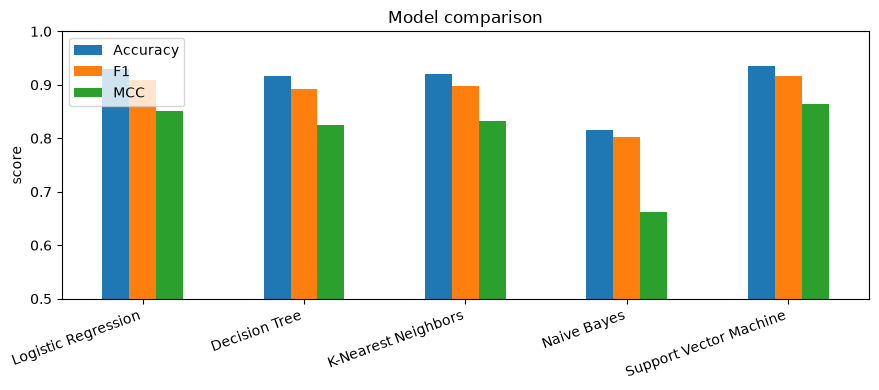

In [11]:
board[["Accuracy","F1","MCC"]].plot.bar(figsize=(9,4))
plt.ylim(0.5,1.0); plt.title("Model comparison"); plt.ylabel("score")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## 8. Confusion matrix - best model

best by F1: Support Vector Machine


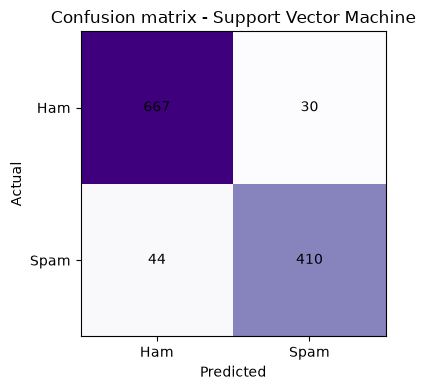

              precision    recall  f1-score   support

         Ham       0.94      0.96      0.95       697
        Spam       0.93      0.90      0.92       454

    accuracy                           0.94      1151
   macro avg       0.93      0.93      0.93      1151
weighted avg       0.94      0.94      0.94      1151



In [12]:
best = board["F1"].idxmax(); print("best by F1:", best)
pred = zoo[best].predict(X_hold)
cm = metrics.confusion_matrix(y_hold, pred)
fig, ax = plt.subplots(figsize=(4.5,4))
im = ax.imshow(cm, cmap="Purples")
ax.set_xticks([0,1], ["Ham","Spam"]); ax.set_yticks([0,1], ["Ham","Spam"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for (i,j),v in np.ndenumerate(cm):
    ax.text(j,i,str(v),ha="center",va="center")
plt.title(f"Confusion matrix - {best}"); plt.tight_layout(); plt.show()
print(metrics.classification_report(y_hold, pred, target_names=["Ham","Spam"]))

## 9. Export hold-out set for the app

In [13]:
hold = X_hold.copy(); hold[LABEL] = y_hold.values
hold.to_csv(root / "sample_test.csv", index=False)
print("sample_test.csv ->", hold.shape)

sample_test.csv -> (1151, 58)


## 10. Observations

| Model | Observation |
|---|---|
| **Logistic Regression** | Strong, well-calibrated linear baseline; high AUC and balanced precision/recall - the log-frequency features are largely linearly separable. |
| **Decision Tree** | Slightly behind the linear/margin models; a single pruned tree (depth 12) captures the obvious keyword rules but misses subtler combinations. |
| **K-Nearest Neighbors** | Competitive after scaling (k=11, distance-weighted); sensitive to the 57-dim feature space but still accurate. |
| **Naive Bayes** | Highest **recall** (catches the most spam) but lowest precision - its feature-independence assumption is violated by correlated word frequencies, so it over-flags ham. |
| **Support Vector Machine** | Best overall on F1, AUC and MCC; the RBF margin handles the high-dimensional, non-linear boundary best. |
| **Winner** | **Support Vector Machine** - top F1 and MCC on the hold-out set. For a spam filter where false positives (ham flagged as spam) are costly, LR or SVM are preferable to Naive Bayes despite NB's high recall. |